# Polynomial Interpolation

## Quadratic Interpolation of sin(x)

(array([-0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ,  1.2]),
 [Text(0, -0.2, '−0.2'),
  Text(0, 0.0, '0.0'),
  Text(0, 0.2, '0.2'),
  Text(0, 0.4000000000000001, '0.4'),
  Text(0, 0.6000000000000001, '0.6'),
  Text(0, 0.8, '0.8'),
  Text(0, 1.0000000000000002, '1.0'),
  Text(0, 1.2000000000000002, '1.2')])

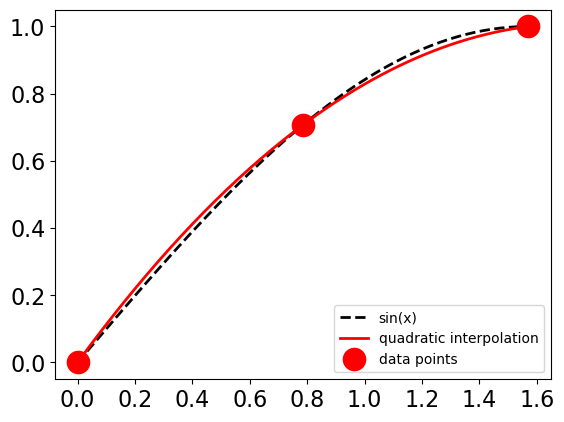

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0, np.pi / 2 + 0.005, 0.01)  # points for plotting
xx = np.array([0, np.pi / 4, np.pi / 2])  # interpolation knots
yy = np.sin(xx)  # interpolation values

p = np.polyfit(xx, yy, 2)

plt.figure()
plt.plot(x, np.sin(x), '--k', x, np.polyval(p, x), '-r', linewidth=2)
plt.plot(xx, yy, 'or', markersize=16)
plt.legend(['sin(x)', 'quadratic interpolation', 'data points'], loc='lower right')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)


(array([-0.005,  0.   ,  0.005,  0.01 ,  0.015,  0.02 ,  0.025,  0.03 ,
         0.035]),
 [Text(0, -0.005, '−0.005'),
  Text(0, 0.0, '0.000'),
  Text(0, 0.005, '0.005'),
  Text(0, 0.009999999999999998, '0.010'),
  Text(0, 0.015, '0.015'),
  Text(0, 0.02, '0.020'),
  Text(0, 0.024999999999999998, '0.025'),
  Text(0, 0.030000000000000002, '0.030'),
  Text(0, 0.035, '0.035')])

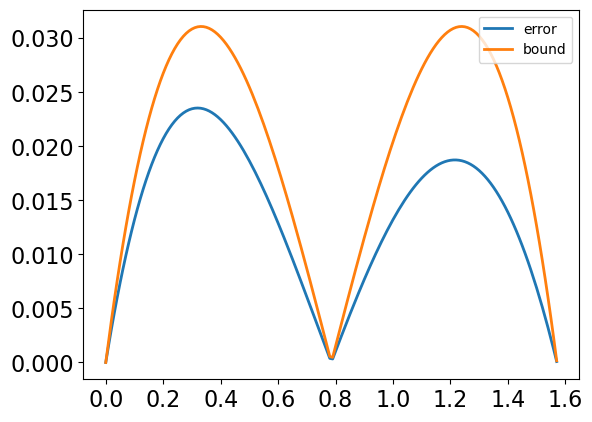

In [3]:
z = np.polyval(p, x)
y = np.sin(x)
err = np.abs(z - y)
fbound = lambda x: x * (x - np.pi / 4) * (x - np.pi / 2) / 6
bound = np.abs(fbound(x))

plt.figure()
plt.plot(x, err, linewidth=2)
plt.plot(x, bound, linewidth=2)
plt.legend(['error', 'bound'], loc='upper right')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)


## Interpolation with different degrees

(array([-0.05,  0.  ,  0.05,  0.1 ,  0.15,  0.2 ,  0.25]),
 [Text(0, -0.05, '−0.05'),
  Text(0, 0.0, '0.00'),
  Text(0, 0.05, '0.05'),
  Text(0, 0.10000000000000002, '0.10'),
  Text(0, 0.15000000000000002, '0.15'),
  Text(0, 0.2, '0.20'),
  Text(0, 0.25000000000000006, '0.25')])

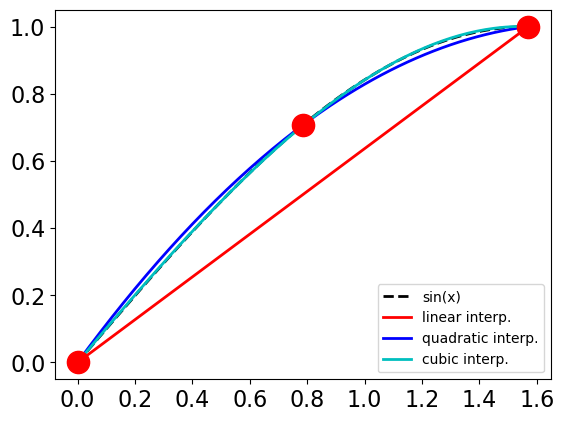

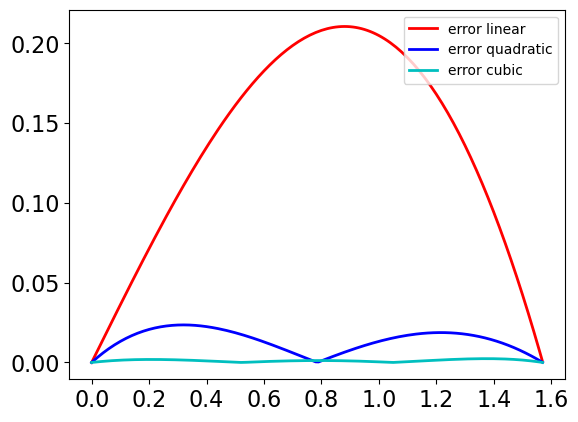

In [4]:
x = np.arange(0, np.pi / 2 + 0.005, 0.01)  # points for plotting
xx1 = np.array([0, np.pi / 2])  # linear interpolation knots
yy1 = np.sin(xx1)
xx2 = np.array([0, np.pi / 4, np.pi / 2])  # quadratic interpolation knots
yy2 = np.sin(xx2)
xx3 = np.array([0, np.pi / 6, np.pi / 3, np.pi / 2])  # cubic interpolation knots
yy3 = np.sin(xx3)

p1 = np.polyfit(xx1, yy1, 1)
p2 = np.polyfit(xx2, yy2, 2)
p3 = np.polyfit(xx3, yy3, 3)

plt.figure(1)
plt.clf()
plt.plot(x, np.sin(x), '--k', x, np.polyval(p1, x), '-r',
         x, np.polyval(p2, x), '-b', x, np.polyval(p3, x), '-c', linewidth=2)
plt.plot(xx, yy, 'or', markersize=16)
plt.legend(['sin(x)', 'linear interp.', 'quadratic interp.', 'cubic interp.'], loc='lower right')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
y = np.sin(x)
err1 = np.abs(np.polyval(p1, x) - y)
err2 = np.abs(np.polyval(p2, x) - y)
err3 = np.abs(np.polyval(p3, x) - y)
plt.figure(2)
plt.clf()
plt.plot(x, err1, '-r', x, err2, '-b', x, err3, '-c', linewidth=2)
plt.legend(['error linear', 'error quadratic', 'error cubic'], loc='upper right')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)


## Interpolation in NumPy/SciPy

NumPy provides multiple ways to do the interpolation, we discuss 2 ways

1: *polyfit* - Fit a curve to given data points -> polynomial. 
   Note: If number of points > polynomial degree: least squares approximation (Ch.5 in lecture notes)

2: *interp - Linear Interpolation between consecutive interpolation points (compare to splines!)

SciPy also provides interpolation functions, e.g. the Cubic spline

(array([-0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ,  1.2]),
 [Text(0, -0.2, '−0.2'),
  Text(0, 0.0, '0.0'),
  Text(0, 0.2, '0.2'),
  Text(0, 0.4000000000000001, '0.4'),
  Text(0, 0.6000000000000001, '0.6'),
  Text(0, 0.8, '0.8'),
  Text(0, 1.0000000000000002, '1.0'),
  Text(0, 1.2000000000000002, '1.2')])

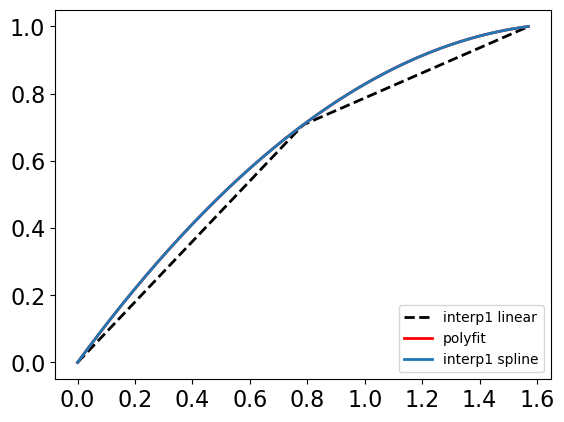

In [5]:
from scipy.interpolate import CubicSpline

x = np.arange(0, np.pi / 2 + 0.005, 0.01)
xx = np.array([0, np.pi / 4, np.pi / 2])
yy = np.sin(xx)

ip = np.interp(x, xx, yy)
ips = CubicSpline(xx, yy, bc_type='not-a-knot')(x)
pp = np.polyfit(xx, yy, 2)

plt.figure()
plt.plot(x, ip, '--k', x, np.polyval(pp, x), '-r', linewidth=2)
plt.plot(x, ips, linewidth=2)
plt.legend(['interp1 linear', 'polyfit', 'interp1 spline'], loc='lower right')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)


In [6]:
help(np.polyfit)


Help on _ArrayFunctionDispatcher in module numpy:

polyfit(x, y, deg, rcond=None, full=False, w=None, cov=False)
    Least squares polynomial fit.

    .. note::
       This forms part of the old polynomial API. Since version 1.4, the
       new polynomial API defined in `numpy.polynomial` is preferred.
       A summary of the differences can be found in the
       :doc:`transition guide </reference/routines.polynomials>`.

    Fit a polynomial ``p(x) = p[0] * x**deg + ... + p[deg]`` of degree `deg`
    to points `(x, y)`. Returns a vector of coefficients `p` that minimises
    the squared error in the order `deg`, `deg-1`, ... `0`.

    The `Polynomial.fit <numpy.polynomial.polynomial.Polynomial.fit>` class
    method is recommended for new code as it is more stable numerically. See
    the documentation of the method for more information.

    Parameters
    ----------
    x : array_like, shape (M,)
        x-coordinates of the M sample points ``(x[i], y[i])``.
    y : array_like, sh

In [4]:
help(np.polyval)


Help on _ArrayFunctionDispatcher in module numpy:

polyval(p, x)
    Evaluate a polynomial at specific values.

    .. note::
       This forms part of the old polynomial API. Since version 1.4, the
       new polynomial API defined in `numpy.polynomial` is preferred.
       A summary of the differences can be found in the
       :doc:`transition guide </reference/routines.polynomials>`.

    If `p` is of length N, this function returns the value:

        ``p[0]*x**(N-1) + p[1]*x**(N-2) + ... + p[N-2]*x + p[N-1]``

    If `x` is a sequence, then ``p(x)`` is returned for each element of ``x``.
    If `x` is another polynomial then the composite polynomial ``p(x(t))``
    is returned.

    Parameters
    ----------
    p : array_like or poly1d object
       1D array of polynomial coefficients (including coefficients equal
       to zero) from highest degree to the constant term, or an
       instance of poly1d.
    x : array_like or poly1d object
       A number, an array of numbers, or

In [5]:
help(np.interp)


Help on _ArrayFunctionDispatcher in module numpy:

interp(x, xp, fp, left=None, right=None, period=None)
    One-dimensional linear interpolation for monotonically increasing sample points.

    Returns the one-dimensional piecewise linear interpolant to a function
    with given discrete data points (`xp`, `fp`), evaluated at `x`.

    Parameters
    ----------
    x : array_like
        The x-coordinates at which to evaluate the interpolated values.

    xp : 1-D sequence of floats
        The x-coordinates of the data points, must be increasing if argument
        `period` is not specified. Otherwise, `xp` is internally sorted after
        normalizing the periodic boundaries with ``xp = xp % period``.

    fp : 1-D sequence of float or complex
        The y-coordinates of the data points, same length as `xp`.

    left : optional float or complex corresponding to fp
        Value to return for `x < xp[0]`, default is `fp[0]`.

    right : optional float or complex corresponding to 

In [6]:
help(CubicSpline)

Help on class CubicSpline in module scipy.interpolate._cubic:

class CubicSpline(CubicHermiteSpline)
 |  CubicSpline(x, y, axis=0, bc_type='not-a-knot', extrapolate=None)
 |
 |  Cubic spline data interpolator.
 |
 |  Interpolate data with a piecewise cubic polynomial which is twice
 |  continuously differentiable [1]_. The result is represented as a `PPoly`
 |  instance with breakpoints matching the given data.
 |
 |  Parameters
 |  ----------
 |  x : array_like, shape (n,)
 |      1-D array containing values of the independent variable.
 |      Values must be real, finite and in strictly increasing order.
 |  y : array_like
 |      Array containing values of the dependent variable. It can have
 |      arbitrary number of dimensions, but the length along ``axis``
 |      (see below) must match the length of ``x``. Values must be finite.
 |  axis : int, optional
 |      Axis along which `y` is assumed to be varying. Meaning that for
 |      ``x[i]`` the corresponding values are ``np.tak